# 01 · Busca semântica: recall@1, recall@3 e limiar de recusa

Item 03 da rubrica. A busca transforma pergunta e trechos em vetores (`bge-m3`, multilíngue) e ordena os trechos por similaridade de cosseno. Medimos se o trecho certo aparece em 1º lugar (recall@1) ou entre os 3 primeiros (recall@3), e escolhemos o **limiar**: abaixo dele o sistema recusa sem chamar o LLM.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import pandas as pd
pd.set_option('display.max_colwidth', 120)
from src import config
from src.busca import Indice
from src.avaliar import carregar_perguntas
indice = Indice()
perguntas = carregar_perguntas()
indice.pre_calcular([p['pergunta'] for p in perguntas])  # vetoriza as perguntas uma vez (cache)
print(len(indice.trechos), 'trechos |', len(perguntas), 'perguntas | LLM:', config.MODELO_LLM, '| embeddings:', config.MODELO_EMB)

32 trechos | 36 perguntas | LLM: qwen2.5:3b | embeddings: bge-m3


In [2]:
linhas = []
for p in perguntas:
    achados = indice.buscar(p['pergunta'], k=3)
    ids = [t['id'] for t, _ in achados]
    linhas.append({'id': p['id'], 'tipo': p['tipo'], 'pergunta': p['pergunta'], 'esperados': p['trechos'],
                   'top3': ids, 'nota_top1': round(achados[0][1], 3),
                   'acerto@1': ids[0] in p['trechos'], 'acerto@3': any(i in p['trechos'] for i in ids)})
df = pd.DataFrame(linhas)
base = df[df.tipo == 'base']
r1, r3 = base['acerto@1'].mean(), base['acerto@3'].mean()
print(f'recall@1 = {r1:.1%}   recall@3 = {r3:.1%}   (sobre {len(base)} perguntas com resposta na base)')

recall@1 = 88.0%   recall@3 = 100.0%   (sobre 25 perguntas com resposta na base)


### Perguntas em que o trecho certo não veio em 1º lugar

In [3]:
base[~base['acerto@1']][['id', 'pergunta', 'esperados', 'top3', 'nota_top1']]

,id,pergunta,esperados,top3,nota_top1
3,q04,O que acontece se eu pedalar na calçada onde não é permitido?,[ctb-art255],"[r996-art19, ctb-art255, ctb-art58]",0.627
9,q10,Até que velocidade o motor auxiliar de uma bicicleta elétrica pode ajudar?,[r996-art2-iii],"[r996-art2-p1-p4, r996-art2-iii, r996-art4]",0.709
10,q11,Uma bicicleta elétrica pode ter acelerador?,[r996-art2-iii],"[r996-art2-p1-p4, r996-art2-iii, r996-art4]",0.662


### Escolha do limiar

Comparamos a nota do melhor trecho nas perguntas **que têm resposta na base** com a nota nas perguntas **sem resposta** (`nao_consta` e `dinamica`, que dependem de dado ao vivo). O limiar escolhido é o corte que maximiza a acurácia balanceada entre os dois grupos; em empate, o mais baixo (preferimos que o LLM e a verificação decidam recusar a perder uma pergunta legítima).

com resposta: min=0.570 mediana=0.670 | sem resposta: max=0.672 mediana=0.528
limiar escolhido = 0.56  -> 100% das perguntas com resposta passam, 82% das sem resposta são recusadas


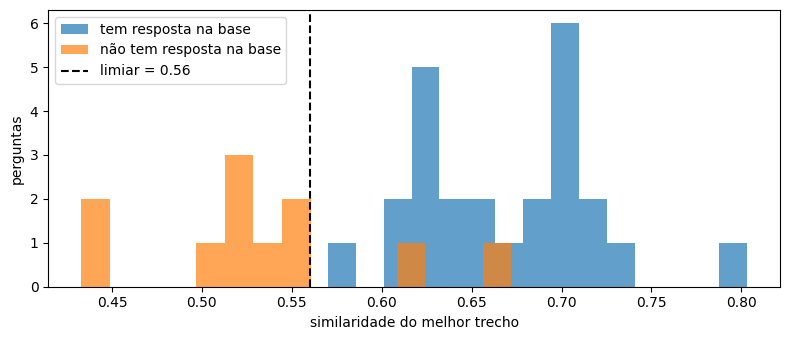

In [4]:
import numpy as np, matplotlib.pyplot as plt
com = df[df.tipo == 'base']['nota_top1'].values
sem = df[df.tipo != 'base']['nota_top1'].values
candidatos = np.round(np.arange(0.30, 0.80, 0.01), 2)
def bal(l): return ((com >= l).mean() + (sem < l).mean()) / 2
notas = [(l, bal(l)) for l in candidatos]
melhor = max(v for _, v in notas)
limiar = min(l for l, v in notas if v == melhor)
print(f'com resposta: min={com.min():.3f} mediana={np.median(com):.3f} | sem resposta: max={sem.max():.3f} mediana={np.median(sem):.3f}')
print(f'limiar escolhido = {limiar:.2f}  -> {(com >= limiar).mean():.0%} das perguntas com resposta passam, {(sem < limiar).mean():.0%} das sem resposta são recusadas')
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(com, bins=15, alpha=.7, label='tem resposta na base')
ax.hist(sem, bins=15, alpha=.7, label='não tem resposta na base')
ax.axvline(limiar, color='k', ls='--', label=f'limiar = {limiar:.2f}')
ax.set_xlabel('similaridade do melhor trecho'); ax.set_ylabel('perguntas'); ax.legend(); plt.tight_layout(); plt.show()
_ = (config.AVALIACAO / 'limiar.json').write_text(json.dumps({'limiar': float(limiar), 'recall@1': round(float(r1), 4), 'recall@3': round(float(r3), 4),
    'acuracia_balanceada': round(float(melhor), 4)}, indent=1), encoding='utf-8')

### Perguntas do lado errado do limiar

In [5]:
df[((df.tipo == 'base') & (df.nota_top1 < limiar)) | ((df.tipo != 'base') & (df.nota_top1 >= limiar))][['id', 'tipo', 'pergunta', 'top3', 'nota_top1']]

,id,tipo,pergunta,top3,nota_top1
31,q32,nao_consta,Em quantos dias a prefeitura é obrigada a tapar o buraco depois do pedido?,"[sp156-limites, sp156-canais, sp156-processo]",0.610
34,q35,dinamica,Tem algum alerta crítico ativo nas ciclovias agora?,"[faq-chuva-seguranca, faq-alertas, faq-cobertura]",0.672
